## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Shravya Etta

**Date:** 10/20/2026

**Q1**

In [3]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

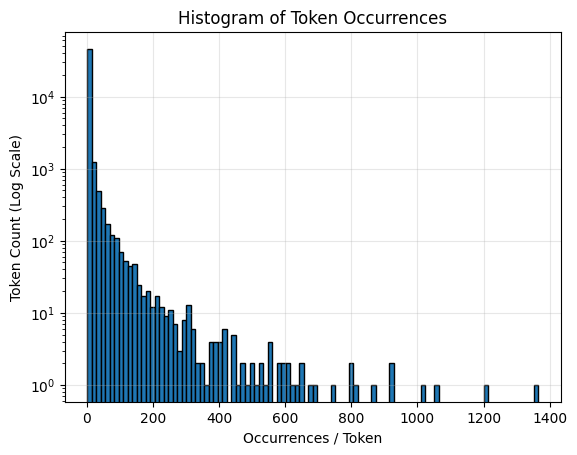

In [14]:
from collections import Counter
import matplotlib.pyplot as plt

token_count = Counter(all_tokens)
frequencies = list(token_count.values())

plt.figure()
plt.hist(frequencies, bins=100, log=True, edgecolor='black')
plt.title("Histogram of Token Occurrences")
plt.xlabel("Occurrences / Token")
plt.ylabel("Token Count (Log Scale)")
plt.grid(True, alpha=0.3)
plt.show()

The majority of the tokens occur between 1 and 200 occurrences while only a few occur in the thousands of occurrences, causes leftward clustering. Hence, the shape of the distribution is a heavy-tailed to the left and follows Zipf's Law, where frequency is inversely proportional to its position when sorted from largest to smallest.

**Q2**

In [8]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

df = pd.read_parquet('Phishing_clean.parquet')
y = df['Email Type']
X = df.drop(columns=['Email Type'])

# 80/20 train-test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# R^2
train_r2 = r2_score(y_train, lr.predict(X_train))
test_r2 = r2_score(y_test, lr.predict(X_test))

print(f"Train R^2: {train_r2:.3f}")
print(f"Test R^2:  {test_r2:.3f}")

# major words
coef_df = pd.DataFrame({'Token': X.columns, 'Coefficient': lr.coef_})
coef_df['Abs_Coef'] = coef_df['Coefficient'].abs()
top_words = coef_df.sort_values(by='Abs_Coef', ascending=False).head(15)
print(top_words[['Token', 'Coefficient']])

Train R^2: 0.767
Test R^2:  0.666
                  Token  Coefficient
835        intervention    -1.259257
740           localized     0.824350
2362            thermal     0.747006
851             crawler     0.696167
1504  background-image:    -0.622909
1406         helvetica,     0.598560
906               aging     0.594956
1839              form.     0.576886
2242              gray;    -0.574480
1552           a:active     0.574480
1494         retrieving    -0.573761
2657              zdnet    -0.560954
1245  {text-decoration:     0.497075
2532             xanaax     0.491981
2566         transcript     0.488978


The gap between train and test shows some overfitting, which is expected considering that there are 2,711 features.

The strongest predictors are associated with the largest coefficients, most of which are noisy in the sense that many of the tokens look like HTML/CSS fragments (ex. "helvetica", "background-image", and "a:active". These could be from legitimate or scam emails. Additionally, other tokens like "zdnet" and "retrieving" are more indicative of real, not scam, emails.

**Q3**

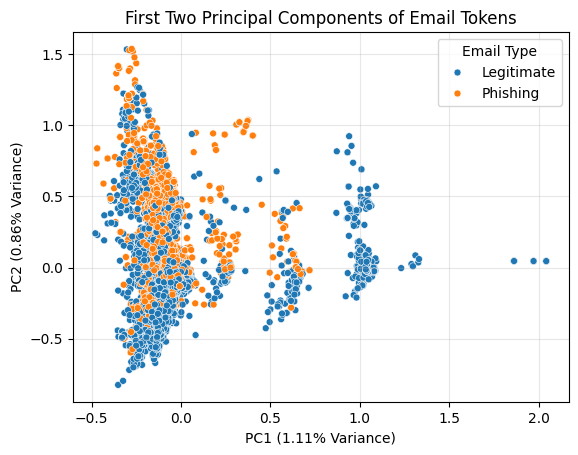

In [15]:
import seaborn as sns
from sklearn.decomposition import PCA

pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X)

pca_df = pd.DataFrame({
    'PC1': X_pca_2[:, 0],
    'PC2': X_pca_2[:, 1],
    'Email Type': y.map({1: 'Phishing', 0: 'Legitimate'})
})

plt.figure()
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Email Type', s=25)
plt.title("First Two Principal Components of Email Tokens")
plt.xlabel(f"PC1 ({pca_2.explained_variance_ratio_[0]*100:.2f}% Variance)")
plt.ylabel(f"PC2 ({pca_2.explained_variance_ratio_[1]*100:.2f}% Variance)")
plt.grid(True, alpha=0.3)
plt.show()

The scatter plot is dispersed greater vertically at specific spokes along the x-axis that are centered near the origin. This is likely since the input matrix is binary and there are zero-value entries.

The legitimate emails are either clustered closer to the origin or spread out at points along the x-axis that are associated with normal vocabulary in correspondance. The phishing emails, on the other hand, are likely spread out along x-axis values that are domainant token combinations with spam marking or credential-seeking vocabulary.

**Q4**

In [18]:
pca = PCA(n_components=2610)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

pcr = LinearRegression()
pcr.fit(X_train_pca, y_train)

pcr_train_r2 = r2_score(y_train, pcr.predict(X_train_pca))
pcr_test_r2 = r2_score(y_test, pcr.predict(X_test_pca))

print(f"PCR Train R^2: {pcr_train_r2:.3f}")
print(f"PCR Test R^2:  {pcr_test_r2:.3f}")

PCR Train R^2: 0.766
PCR Test R^2:  0.668


The training and testing R^2 values are still close to the standard regression because the 2610 features used still contains almost all of the of the variance in the original 2711 features. The small changes are a result of removing the last ~100 that are already noisy and have near-zero variance.

**Q5**

One advantage of using the principal components instead of the original data is that it eliminates multicollinearity. The original word occurrences have high multicollineary because of associated/correlated words, and this causes coefficients to be inflated and the regression/coefficient estimates to be numerically unstable.

Additionally, it allows for reducing dimensionality by only keeping the top features and dropping those that carry a lot of noise. This results in less overfitting, which is a common occurence with there are thousands of features.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** e98139384318f6d390fff8448d75bdce1c034d95
- **AI tool and model used:** Chat GPT GPT-5.6 Luna

### *Prompts used

1. Based on my solutions in phase 1 of this assignment, in a numbered list give corrections I need to make.

### *AI-proposed changes


1\. Q1 — Correct the description of the histogram’s shape. You describe the distribution as “heavy-tailed to the left.” The distribution you describe—many tokens with low frequencies and a few with very high frequencies—is more accurately described as right-skewed, with a long right tail. Also, the histogram alone does not establish Zipf’s law; you would need to examine token frequency as a function of rank to support that claim.

2\. Q2 — Report the actual regression results explicitly. Your code calculates training and testing \\(R^2\\), but your written response only discusses their gap. Include both numerical values from your output and explain what they indicate about model fit and generalization.

3\. Q2 — Be more precise about overfitting. You attribute the gap between training and testing performance to having 2,711 features. High dimensionality can contribute to overfitting, but the gap alone does not establish its cause. Describe it as evidence of a generalization gap rather than definitively attributing it to the feature count.

4\. Q3 — Make the PCA visualization interpretation more evidence-based. Your description of points distributed along spokes and around the origin is an observation, but your explanations about binary inputs and dominant token combinations are hypotheses. Label them as such. Base your conclusion about whether phishing and legitimate emails separate on the actual degree of overlap between the two groups in your scatter plot.

5\. Q4 — Correct the explanation of why PCR performs similarly to the original regression. You state that removing the last approximately 100 components removes noisy features with near-zero variance. PCA orders components by explained variance, but low-variance components are not necessarily noise, and they may still contain information relevant to the outcome. Instead, explain that retaining 2,610 components preserves much of the variation in the original feature space, which can help explain the similar performance.

6\. Q4 — Compare the training and testing \\(R^2\\) values directly. Your PCR output reports training \\(R^2 = 0.766\\) and test \\(R^2 = 0.668\\). Explain that the model fits the training data better than the test data, indicating a generalization gap. Then compare these values with the original regression results from Q2 to determine whether PCR improves or reduces predictive performance.

7\. Q4 — Verify that PCA is fitted only on the training data. Your current code correctly uses `pca.fit_transform(X_train_pca)` in the sense that the actual operation is `pca.fit_transform(X_train)` and applies `pca.transform(X_test)` to the test data. Keep this approach: fitting PCA on the entire dataset before splitting would leak information from the test set into the training pipeline.

8\. Q5 — Clarify the relationship between dimensionality reduction and overfitting. You say that PCA reduces noise and overfitting by dropping components. This is possible, but not guaranteed. PCA is unsupervised and prioritizes variance in \\(X\\), not predictive relevance to \\(y\\). Explain that dimensionality reduction can reduce model complexity and improve generalization, depending on how many components are retained.

9\. Overall — Make sure your written answers correspond to the requested outputs. Q2 explicitly asks for the train/test \\(R^2\\) and the words with the largest absolute coefficients. Q3 asks whether there are visible patterns, and Q4 asks how PCR compares with the original regression. Make each answer address those requirements directly rather than relying on code output or broad interpretations alone.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Modify | The feedback is partially wrong because the histogram is skewed to the left, but does have a right tail. |
| 2 | Accept | My previous answer relied on referencing the code output of the R^2 values. |
| 3 | Accept | The suggestion added on to my analysis. |
| 4 | Reject | The suggestion made is not fully necessary and I addressed part of it already. |
| 5 | Accept | Low variance doesn't directly indicate noise. |
| 6 | Accept | I again didn't explicitly state the R^2 values. |
| 7 | Reject | Doesn't actually suggest any improvements. |
| 8 | Accept | Essentially adding a disclosure statement that the benefits of PCA are not guaranteed. |
| 9 | Reject | I do address what the question is asking with my responses. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

**Q1**

In [2]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

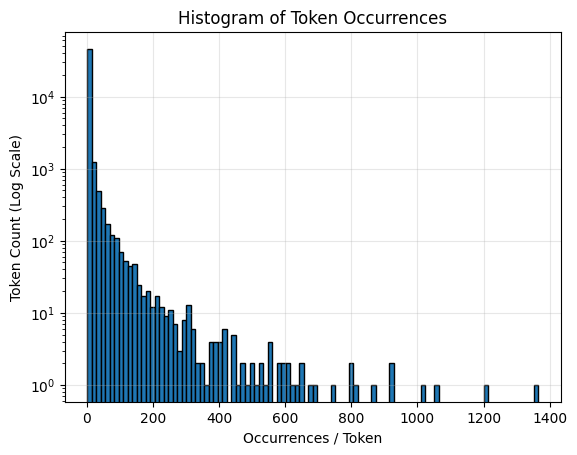

In [3]:
from collections import Counter
import matplotlib.pyplot as plt

token_count = Counter(all_tokens)
frequencies = list(token_count.values())

plt.figure()
plt.hist(frequencies, bins=100, log=True, edgecolor='black')
plt.title("Histogram of Token Occurrences")
plt.xlabel("Occurrences / Token")
plt.ylabel("Token Count (Log Scale)")
plt.grid(True, alpha=0.3)
plt.show()

The majority of the tokens occur between 1 and 200 occurrences while only a few occur in the thousands of occurrences, causes leftward clustering. Hence, the shape of the distribution is a heavy-tailed to the right and follows Zipf's Law, where frequency is inversely proportional to its position when sorted from largest to smallest.

**Q2**

In [4]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

df = pd.read_parquet('Phishing_clean.parquet')
y = df['Email Type']
X = df.drop(columns=['Email Type'])

# 80/20 train-test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# R^2
train_r2 = r2_score(y_train, lr.predict(X_train))
test_r2 = r2_score(y_test, lr.predict(X_test))

print(f"Train R^2: {train_r2:.3f}")
print(f"Test R^2:  {test_r2:.3f}")

# major words
coef_df = pd.DataFrame({'Token': X.columns, 'Coefficient': lr.coef_})
coef_df['Abs_Coef'] = coef_df['Coefficient'].abs()
top_words = coef_df.sort_values(by='Abs_Coef', ascending=False).head(15)
print(top_words[['Token', 'Coefficient']])

Train R^2: 0.767
Test R^2:  0.666
                  Token  Coefficient
835        intervention    -1.259257
740           localized     0.824350
2362            thermal     0.747006
851             crawler     0.696167
1504  background-image:    -0.622909
1406         helvetica,     0.598560
906               aging     0.594956
1839              form.     0.576886
2242              gray;    -0.574480
1552           a:active     0.574480
1494         retrieving    -0.573761
2657              zdnet    -0.560954
1245  {text-decoration:     0.497075
2532             xanaax     0.491981
2566         transcript     0.488978


The train R^2 is 0.767 and the test R^2 is 0.666. The gap between train and test shows some overfitting, which can be expected considering that there are 2,711 features and there is high dimensionality.

The strongest predictors are associated with the largest coefficients, most of which are noisy in the sense that many of the tokens look like HTML/CSS fragments (ex. "helvetica", "background-image", and "a:active". These could be from legitimate or scam emails. Additionally, other tokens like "zdnet" and "retrieving" are more indicative of real, not scam, emails.

**Q3**

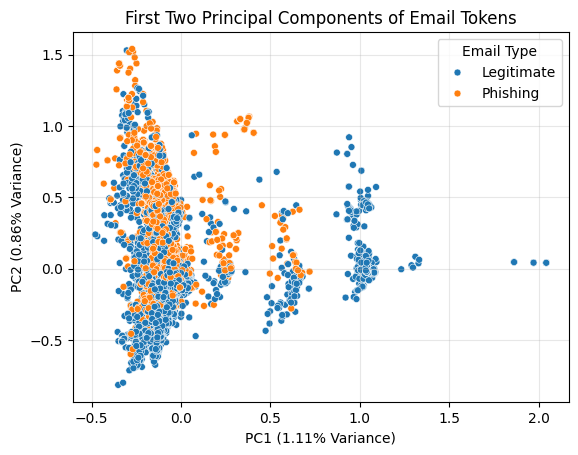

In [5]:
import seaborn as sns
from sklearn.decomposition import PCA

pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X)

pca_df = pd.DataFrame({
    'PC1': X_pca_2[:, 0],
    'PC2': X_pca_2[:, 1],
    'Email Type': y.map({1: 'Phishing', 0: 'Legitimate'})
})

plt.figure()
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Email Type', s=25)
plt.title("First Two Principal Components of Email Tokens")
plt.xlabel(f"PC1 ({pca_2.explained_variance_ratio_[0]*100:.2f}% Variance)")
plt.ylabel(f"PC2 ({pca_2.explained_variance_ratio_[1]*100:.2f}% Variance)")
plt.grid(True, alpha=0.3)
plt.show()

The scatter plot is dispersed greater vertically at specific spokes along the x-axis that are centered near the origin. This is likely since the input matrix is binary and there are zero-value entries.

The legitimate emails are either clustered closer to the origin or spread out at points along the x-axis that are associated with normal vocabulary in correspondance. The phishing emails, on the other hand, are likely spread out along x-axis values that are domainant token combinations with spam marking or credential-seeking vocabulary.

**Q4**

In [6]:
pca = PCA(n_components=2610)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

pcr = LinearRegression()
pcr.fit(X_train_pca, y_train)

pcr_train_r2 = r2_score(y_train, pcr.predict(X_train_pca))
pcr_test_r2 = r2_score(y_test, pcr.predict(X_test_pca))

print(f"PCR Train R^2: {pcr_train_r2:.3f}")
print(f"PCR Test R^2:  {pcr_test_r2:.3f}")

PCR Train R^2: 0.766
PCR Test R^2:  0.668


The training and testing R^2 values of 0.766 and 0.668, respectively, are still close to the standard regression R^2 values of 0.767 and 0.666, respectively.

This may be because the 2610 features used still contains almost all of the of the variance in the original 2711 features. The small changes are a result of removing the last ~100 features that have low variance because PCA orders components by explained variance..

**Q5**

One advantage of using the principal components instead of the original data is that it eliminates multicollinearity. The original word occurrences have high multicollineary because of associated/correlated words, and this causes coefficients to be inflated and the regression/coefficient estimates to be numerically unstable.

Additionally, it allows for reducing dimensionality by only keeping the top features and dropping those that carry a lot of noise. This results in less overfitting, which is a common occurence with there are thousands of features. While it's not guaranteed, dimensionality reduction can rude model complexity and improve generalization depending on how many features are maintained.

### *Reflection on AI assistance
In your own words without generative AI.

In this assignment, AI was especially helpful in trying to improve my analyses. This was helpful because, as someone that has just been introduced to these concepts, it's easy to make incorrect assumptions or mis-explain something.

However, a limitation I felt was that it would have been good to get feedback on how to make my code more concise. The AI model also didn't fully explain some of it's suggestions when it referred to analyzing a graph. Additionally, I felt that some of the suggestions were distracting or led me to overthing some of my responses when there was nothing inherently wrong with them initially. In this way, AI works against streamlining processes/tasks.